# UNIVERSIDAD TÉCNICA PARTICULAR DE LOJA (UTPL)
## Interoperabilidad y Explotación de Datos en Ecosistemas Heterogéneos
**Docente:** Dra. Janneth Alexandra Chicaiza Espinosa
**Integrantes:** Alex Gutiérrez, David Manotoa
**Fecha:** 27 de noviembre de 2026 (versión final)

---
# Entregable 3: Generación de datos RDF
**Dominio:** Smart City Barcelona — movilidad (CityBikes / Bicing), calidad del aire (Open-Meteo / CAMS)
y barrios y distritos (Open Data BCN).

## 1. Objetivo y flujo de trabajo

Convertir los datos extraídos y limpiados a **RDF (Turtle)**, siguiendo el modelo **v3**
(`E3_rdf/modelo/vocab.ttl` y `modelo_datos.png`), almacenarlos en **un solo grafo** de **GraphDB**, comprobar la
integración entre movilidad y calidad del aire y responder las 15 preguntas de competencia con SPARQL. El informe sin código está en `E3_rdf/informe/informe_proyecto.html`.

| Paso | Qué se hace | Código |
|---|---|---|
| 1 | Configuración y prefijos del modelo | `generar_rdf.PREFIJOS` |
| 2 | Revisión de los datos de entrada (nulos, duplicados) | `pandas` |
| 3 | Preprocesamiento: celdas CAMS y barrios de cada estación | `preprocesar.py` |
| 4 | Esquema de identificación de URIs | `normalizar`, `uri_*` |
| 5 | Prueba con 2 filas | `ejecutar(limite=2)` |
| 6 | Generación Fuente 1 (Bicing), Fuente 2 (CAMS) y Fuente 3 (barrios) | `generar_bicing`, `generar_calidad_aire`, `generar_barrios` |
| 7 | Validación contra el modelo | `validar` |
| 8 | Serialización y totales por clase | `serialize`, SPARQL |
| 9 | Integración movilidad + calidad del aire | `sparql/05`, `06`, `07` |
| 10 | Almacenamiento en GraphDB | `cargar_graphdb.py` (API REST) |
| 11 | Preguntas de competencia PC1–PC15 | `sparql/pcNN.rq` |

Toda la lógica está en `E3_rdf/scripts/` (funciones documentadas y probadas con `pytest`);
el notebook la ejecuta paso a paso y muestra el resultado de cada bloque.

## 2. Configuración del entorno

In [1]:
import sys, inspect
from pathlib import Path
from IPython.display import Markdown, display

DIR_E3 = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(DIR_E3 / 'scripts'))

import pandas as pd
import rdflib
import matplotlib.pyplot as plt
import preprocesar
import generar_rdf as gen
import cargar_graphdb

def ver_codigo(funcion):
    """Muestra el código fuente de una función del proyecto dentro del notebook."""
    display(Markdown(f"```python\n{inspect.getsource(funcion)}```"))

print('rdflib', rdflib.__version__, '| pandas', pd.__version__)
print('Datos de entrada:', gen.DIR_PROCESADOS.relative_to(gen.RAIZ))

rdflib 7.6.0 | pandas 3.1.1
Datos de entrada: datos/procesados


## 3. Prefijos del modelo

Antes de crear tripletas se registran los prefijos de **todo** lo que aparece en el modelo:
el de nuestros datos (`data:`), el de nuestro vocabulario (`vocab:`) y los vocabularios reutilizados.
`RDF`, `RDFS`, `XSD` y `DCTERMS` vienen precargados en rdflib; `schema:`, `sosa:` y `geo:` se
definen manualmente con `Namespace`, igual que `data:` y `vocab:`.

> Una sola URI base (`http://example.org/bcn-kg/data/`) para **las tres fuentes**: así los nodos
> comunes (estaciones, barrios, celdas CAMS) son el mismo nodo en todos los archivos y el grafo queda enlazado.

In [2]:
pd.DataFrame([(p, str(ns)) for p, ns in gen.PREFIJOS.items()], columns=['Prefijo', 'Namespace'])

,Prefijo,Namespace
0,data,http://example.org/bcn-kg/data/
1,vocab,http://example.org/bcn-kg/vocab#
2,schema,https://schema.org/
3,sosa,http://www.w3.org/ns/sosa/
4,geo,http://www.w3.org/2003/01/geo/wgs84_pos#
5,dcterms,http://purl.org/dc/terms/
6,rdfs,http://www.w3.org/2000/01/rdf-schema#
7,xsd,http://www.w3.org/2001/XMLSchema#
8,dbr,http://dbpedia.org/resource/


Modelo v3 (final), con las correcciones de la docente:
- lo dinámico (estado de una estación y medición de aire) es **`schema:Observation`**, con `schema:observationAbout`;
- cada vínculo usa **una sola relación** reutilizada (sin subpropiedades propias): toda ubicación es `schema:containedInPlace`
  (Estación → Barrio → Distrito → Barcelona, y Estación → Celda CAMS);
- la red Bicing es una instancia con nombre y todas las instancias llevan `rdfs:label`.

Clases y atributos propios definidos en `vocab.ttl`:

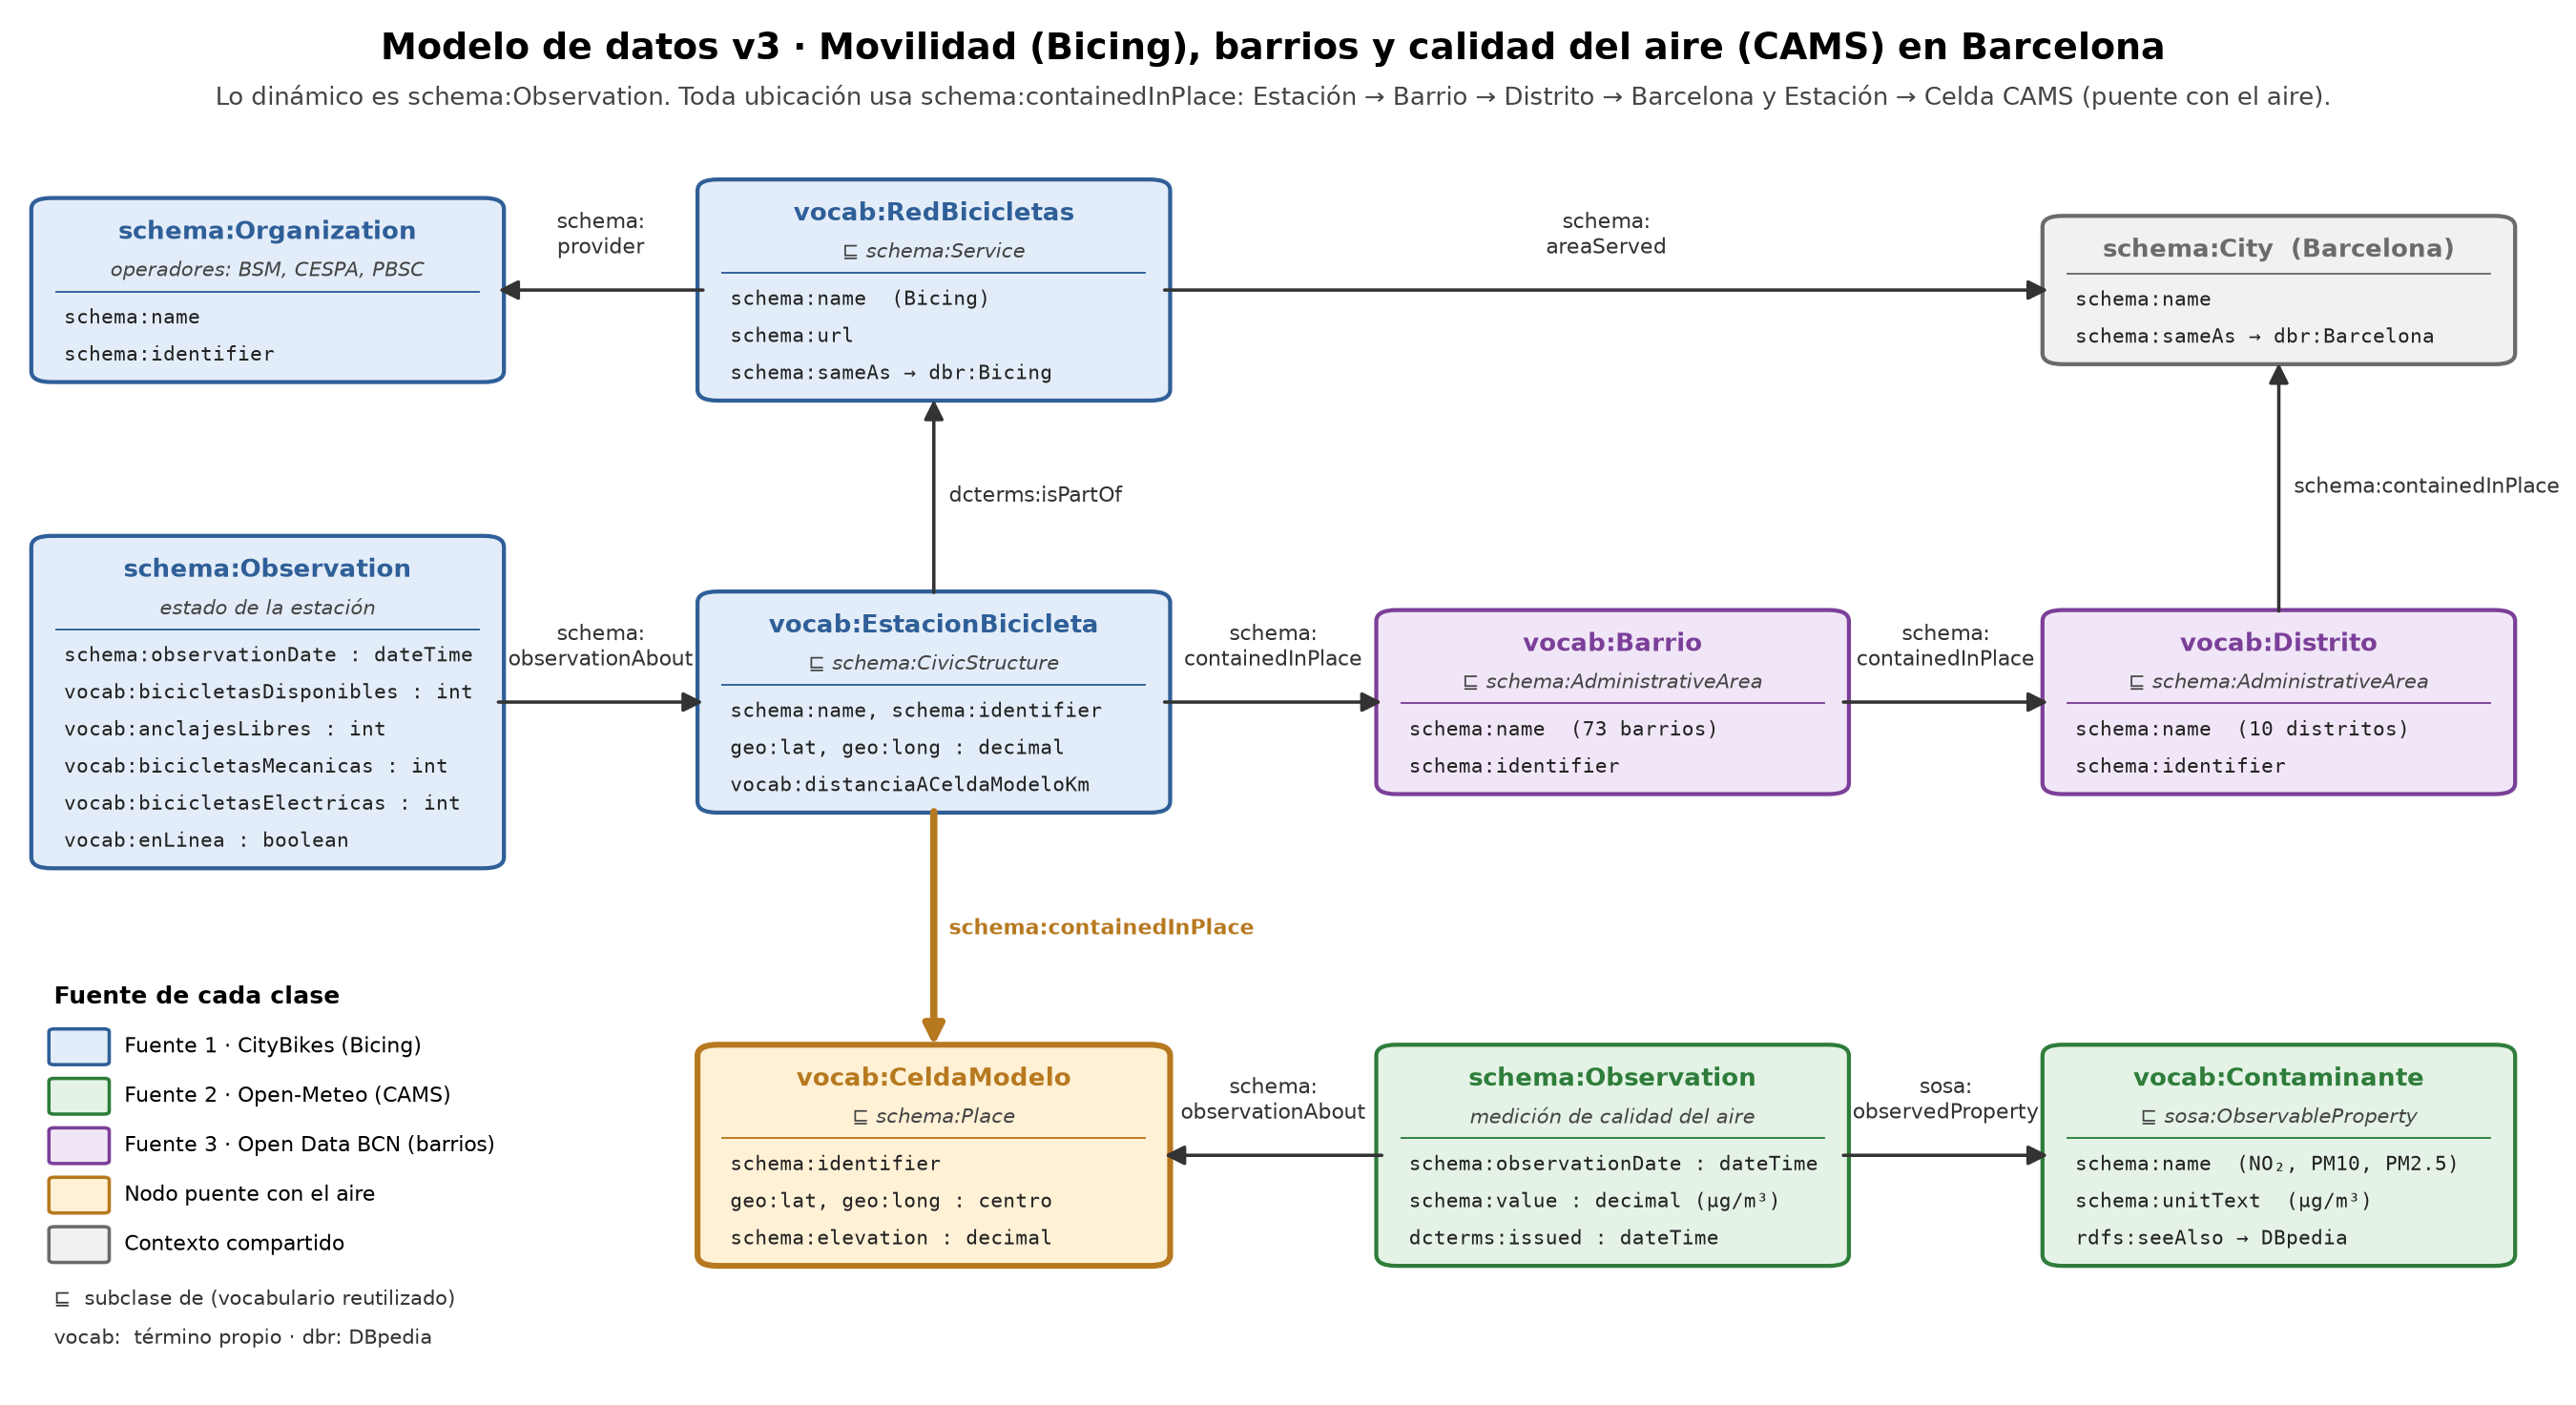

In [3]:
from IPython.display import Image
Image(filename=str(DIR_E3 / 'modelo' / 'modelo_datos.png'), width=1000)

In [4]:
vocab = rdflib.Graph().parse(gen.RUTA_VOCAB)
RDF, RDFS = rdflib.RDF, rdflib.RDFS
filas = []
for p in vocab.subjects(RDF.type, RDF.Property):
    filas.append((p.n3(vocab.namespace_manager),
                  vocab.value(p, RDFS.domain).n3(vocab.namespace_manager),
                  vocab.value(p, RDFS.range).n3(vocab.namespace_manager)))
clases = sorted(c.n3(vocab.namespace_manager) for c in vocab.subjects(RDF.type, RDFS.Class))
print('Clases propias:', ', '.join(clases))
pd.DataFrame(sorted(filas), columns=['Propiedad', 'Dominio', 'Rango'])

Clases propias: vocab:Barrio, vocab:CeldaModelo, vocab:Contaminante, vocab:Distrito, vocab:EstacionBicicleta, vocab:RedBicicletas


,Propiedad,Dominio,Rango
0,vocab:anclajesLibres,schema:Observation,xsd:nonNegativeInteger
1,vocab:bicicletasDisponibles,schema:Observation,xsd:nonNegativeInteger
2,vocab:bicicletasElectricas,schema:Observation,xsd:nonNegativeInteger
3,vocab:bicicletasMecanicas,schema:Observation,xsd:nonNegativeInteger
4,vocab:distanciaACeldaModeloKm,vocab:EstacionBicicleta,xsd:decimal
5,vocab:enLinea,schema:Observation,xsd:boolean


## 4. Revisión de los datos de entrada

Todos los datos están en `datos/procesados/` (11 CSV definitivos, descritos en `datos/README.md`).
Aquí se revisan los de CityBikes que vienen de la limpieza del Entregable 2: filas, duplicados por clave
y valores nulos. Los de calidad del aire (`cams_*.csv`), los de barrios (`bcn_*.csv`) y los enlaces
se generan en la sección 5.

In [5]:
claves = {
    'citybikes_estaciones': ['id_estacion'],
    'citybikes_estado': ['id_estacion', 'captura_utc'],
    'citybikes_operadores': ['id_operador'],
    'procedencia': ['archivo_raw'],
}
resumen = []
for nombre, clave in claves.items():
    df = pd.read_csv(gen.DIR_PROCESADOS / f'{nombre}.csv')
    resumen.append({'archivo': nombre, 'filas': len(df),
                    'duplicados_clave': int(df.duplicated(clave).sum()),
                    'celdas_nulas': int(df.isna().sum().sum())})
pd.DataFrame(resumen)

,archivo,filas,duplicados_clave,celdas_nulas
0,citybikes_estaciones,542,0,0
1,citybikes_estado,542,0,0
2,citybikes_operadores,3,0,0
3,procedencia,2,0,0


## 5. Preprocesamiento: corrección de las celdas CAMS

Al revisar los datos se detectó un problema heredado del Entregable 2: **las dos celdas tenían
exactamente los mismos valores de contaminación**. La causa es que Open-Meteo devuelve en
`latitude`/`longitude` una coordenada **redondeada** (41.4, 2.2) que no identifica la celda real.
Se pidieron 6 puntos; 5 respondieron "41.4, 2.2", pero con **3 series distintas**. Al usar esa
coordenada como identificador se fusionaron celdas diferentes y se perdieron 2 series.

In [6]:
import json
ruta_raw = sorted(preprocesar.DIR_RAW_CAMS.glob('*.json'))[-1]
sobre = json.loads(ruta_raw.read_text(encoding='utf-8'))
filas = []
for (lat, lon), item in zip(preprocesar.puntos_solicitados(sobre['url']), sobre['payload']):
    filas.append({'lat_pedida': lat, 'lon_pedida': lon,
                  'lat_reportada': item['latitude'], 'lon_reportada': item['longitude'],
                  'NO2_primeras_3h': item['hourly']['nitrogen_dioxide'][:3],
                  'celda_real': preprocesar.celda_de(lat, lon)[0]})
pd.DataFrame(filas)

,lat_pedida,lon_pedida,lat_reportada,lon_reportada,NO2_primeras_3h,celda_real
0,41.3865,2.1694,41.4,2.200001,"[38.2, 34.9, 31.6]",celda_41.35_2.15
1,41.4055,2.1623,41.4,2.200001,"[47.3, 38.6, 33.1]",celda_41.45_2.15
2,41.3750,2.1400,41.4,2.100000,"[38.2, 34.9, 31.6]",celda_41.35_2.15
3,41.4260,2.1850,41.4,2.200001,"[47.3, 38.6, 33.1]",celda_41.45_2.15
4,41.3980,2.2030,41.4,2.200001,"[29.5, 30.2, 25.6]",celda_41.35_2.25
5,41.3800,2.1900,41.4,2.200001,"[38.2, 34.9, 31.6]",celda_41.35_2.15


**Solución.** La rejilla CAMS Europa es de 0.1° con centros en múltiplos de 0.05. La celda real
se obtiene con `floor(coordenada × 10) / 10` sobre la coordenada **pedida**. La tabla anterior lo
confirma: los puntos con la misma `celda_real` traen exactamente la misma serie. La función
`desanidar_cams` lo **verifica** y falla si no se cumple. Las estaciones se asignan a su celda con
la misma regla (contención exacta, en lugar de "celda más cercana").

In [7]:
ver_codigo(preprocesar.celda_de)
ver_codigo(preprocesar.desanidar_cams)

```python
def celda_de(lat: float, lon: float) -> tuple[str, float, float]:
    """Devuelve (id_celda, lat_centro, lon_centro) de la celda CAMS de 0.1° que contiene el punto."""
    lat0 = math.floor(round(lat / TAMANO_CELDA, 9)) * TAMANO_CELDA
    lon0 = math.floor(round(lon / TAMANO_CELDA, 9)) * TAMANO_CELDA
    lat_c, lon_c = round(lat0 + TAMANO_CELDA / 2, 2), round(lon0 + TAMANO_CELDA / 2, 2)
    return f"celda_{lat_c:.2f}_{lon_c:.2f}", lat_c, lon_c
```

```python
def desanidar_cams(ruta_raw: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Convierte la captura cruda de Open-Meteo en celdas y observaciones atómicas.

    Agrupa los puntos por celda real y comprueba que sus series coinciden.
    """
    sobre = json.loads(ruta_raw.read_text(encoding="utf-8"))
    items = sobre["payload"] if isinstance(sobre["payload"], list) else [sobre["payload"]]
    puntos = puntos_solicitados(sobre["url"])
    if len(puntos) != len(items):
        raise ValueError(f"{len(puntos)} puntos solicitados pero {len(items)} respuestas")

    series: dict[str, dict] = {}
    celdas: dict[str, dict] = {}
    for (lat, lon), item in zip(puntos, items):
        id_celda, lat_c, lon_c = celda_de(lat, lon)
        serie = {k: item["hourly"][k] for k in ["time", *CONTAMINANTES]}
        if id_celda in series:
            if series[id_celda] != serie:
                raise ValueError(f"Puntos de {id_celda} con series distintas: rejilla incorrecta")
            celdas[id_celda]["puntos_muestreo"] += 1
            continue
        series[id_celda] = serie
        celdas[id_celda] = {"id_celda": id_celda, "latitud_celda": lat_c, "longitud_celda": lon_c,
                            "elevacion": float(item.get("elevation", 0.0)), "puntos_muestreo": 1,
                            "unidad": item.get("hourly_units", {})}

    filas = []
    for id_celda, serie in series.items():
        unidades = celdas[id_celda].pop("unidad")
        for i, t in enumerate(serie["time"]):
            hora = pd.Timestamp(t).tz_localize("UTC").isoformat()
            for var, codigo in CONTAMINANTES.items():
                valor = serie[var][i]
                filas.append({"id_celda": id_celda, "hora_utc": hora, "contaminante": codigo,
                              "valor": None if valor is None else float(valor),
                              "unidad": unidades.get(var, "μg/m³")})
    return pd.DataFrame(list(celdas.values())), pd.DataFrame(filas)
```

In [8]:
pre = preprocesar.ejecutar(guardar=True)
print('Celdas resultantes:')
display(pre['cams_celdas'])
print('Estaciones por celda:')
display(pre['enlace_estacion_celda'].groupby(['id_celda', 'celda_con_datos']).size().rename('estaciones').reset_index())
print('Observaciones CAMS:', len(pre['cams_observaciones']), '(3 celdas × 48 horas × 3 contaminantes)')

Celdas resultantes:


,id_celda,latitud_celda,longitud_celda,elevacion,puntos_muestreo
0,celda_41.35_2.15,41.35,2.15,24.0,3
1,celda_41.35_2.25,41.35,2.25,6.0,1
2,celda_41.45_2.15,41.45,2.15,66.0,2
3,celda_41.45_2.25,41.45,2.25,None,0


Estaciones por celda:


,id_celda,celda_con_datos,estaciones
0,celda_41.35_2.15,True,301
1,celda_41.35_2.25,True,6
2,celda_41.45_2.15,True,193
3,celda_41.45_2.25,False,42


Observaciones CAMS: 432 (3 celdas × 48 horas × 3 contaminantes)


**Limitación documentada:** la celda `celda_41.45_2.25` (noreste, 42 estaciones) no fue muestreada en la
captura del Entregable 2. Se crea igualmente como nodo `vocab:CeldaModelo` para que sus estaciones queden
enlazadas, pero no tiene observaciones. Una nueva captura que incluya un punto en esa celda la completaría.

### 5.1 Barrio y distrito de cada estación (Fuente 3: Open Data BCN)

La docente pidió conectar las estaciones con su barrio y el barrio con algo más general. Open Data BCN publica
los 73 barrios con su contorno (polígono WGS84) y su distrito. Cada estación se asigna al barrio cuyo polígono
**contiene** sus coordenadas (prueba punto-en-polígono por trazado de rayos, sin librerías externas).

In [9]:
ver_codigo(preprocesar.dentro)
ver_codigo(preprocesar.ubicar_en_barrios)

```python
def dentro(lon: float, lat: float, anillo: list[tuple[float, float]]) -> bool:
    """Prueba punto-en-polígono por trazado de rayos."""
    resultado, j = False, len(anillo) - 1
    for i in range(len(anillo)):
        (xi, yi), (xj, yj) = anillo[i], anillo[j]
        if (yi > lat) != (yj > lat) and lon < (xj - xi) * (lat - yi) / (yj - yi) + xi:
            resultado = not resultado
        j = i
    return resultado
```

```python
def ubicar_en_barrios(estaciones: pd.DataFrame, poligonos: dict[int, list]) -> pd.DataFrame:
    """Barrio que contiene a cada estación. Si un punto queda justo fuera de todos
    los contornos (p. ej. en el paseo marítimo), se usa el barrio más cercano."""
    def mas_cercano(lon: float, lat: float) -> int:
        return min(poligonos, key=lambda b: min((x - lon) ** 2 + (y - lat) ** 2
                                               for anillo in poligonos[b] for x, y in anillo))
    filas = []
    for e in estaciones.itertuples():
        barrio = next((b for b, anillos in poligonos.items()
                       if any(dentro(e.longitud, e.latitud, a) for a in anillos)), None)
        filas.append({"id_estacion": e.id_estacion,
                      "id_barrio": barrio if barrio is not None else mas_cercano(e.longitud, e.latitud),
                      "dentro_del_contorno": barrio is not None})
    return pd.DataFrame(filas)
```

In [10]:
eb = pre['enlace_estacion_barrio'].merge(pre['bcn_barrios'], on='id_barrio').merge(pre['bcn_distritos'], on='id_distrito')
print('Estaciones dentro del contorno de un barrio:', int(eb.dentro_del_contorno.sum()), 'de', len(eb))
print('Barrios con estaciones:', eb.id_barrio.nunique(), 'de', len(pre['bcn_barrios']))
eb.groupby('nombre_distrito').agg(barrios=('id_barrio', 'nunique'), estaciones=('id_estacion', 'count'))   .sort_values('estaciones', ascending=False)

Estaciones dentro del contorno de un barrio: 542 de 542
Barrios con estaciones: 65 de 73


,barrios,estaciones
nombre_distrito,,
Eixample,6,114
Sant Martí,10,93
Ciutat Vella,4,62
Sants-Montjuïc,8,57
Sant Andreu,7,48
Horta-Guinardó,8,40
Sarrià-Sant Gervasi,5,39
Les Corts,3,37
Nou Barris,10,28


## 6. Esquema de identificación de URIs

Se usa el **nombre o identificador natural** de cada entidad para formar su URI, con dos reglas de formato
(función `normalizar`): quitar tildes y caracteres especiales, y reemplazar espacios por `_`.
La misma función se usa en las tres fuentes, por eso el nodo común se genera idéntico.

| Clase | Patrón de URI | Ejemplo |
|---|---|---|
| `vocab:RedBicicletas` | `data:red_bicing` | `data:red_bicing` |
| `schema:Organization` | `data:organizacion_<nombre>` | `data:organizacion_CESPA` |
| `vocab:EstacionBicicleta` | `data:estacion_<id>` | `data:estacion_00028670…` |
| `schema:Observation` (estado) | `data:estado_<id>_<fecha>` | `data:estado_00028670…_20261112T163024` |
| `vocab:CeldaModelo` | `data:celda_<lat>_<lon>` | `data:celda_41.35_2.15` |
| `vocab:Contaminante` | `data:contaminante_<código>` | `data:contaminante_NO2` |
| `schema:Observation` (aire) | `data:obs_<celda>_<hora>_<código>` | `data:obs_celda_41.35_2.15_20261111T000000_NO2` |
| `vocab:Barrio` | `data:barrio_<código>` | `data:barrio_07` |
| `vocab:Distrito` | `data:distrito_<código>` | `data:distrito_02` |
| `schema:City` | `data:Barcelona` | `data:Barcelona` |

Para las estaciones se usa el `id` de CityBikes y no el nombre, porque los nombres de calle se repiten
(mismo problema que dos personas con el mismo nombre).

In [11]:
ver_codigo(gen.normalizar)
for texto in ['Barcelona de Serveis Municipals, S.A. (BSM)', 'PL  JOANIC - C / BRUNIQUER, 59', 'Universidad Autónoma']:
    print(f'{texto!r:50} -> {gen.normalizar(texto)}')
print(gen.uri_operador('CESPA'))
print(gen.uri_contaminante('PM2_5'))

```python
def normalizar(texto: str) -> str:
    """Formatea un texto para usarlo como nombre local de una URI.

    Quita tildes y diacríticos, reemplaza espacios y símbolos por '_' y
    elimina guiones bajos sobrantes. Es la MISMA regla para todas las fuentes.
    Ejemplo: 'Barcelona de Serveis Municipals, S.A. (BSM)'
             -> 'Barcelona_de_Serveis_Municipals_S.A._BSM'
    """
    ascii_ = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9._-]+", "_", ascii_).strip("_")
```

'Barcelona de Serveis Municipals, S.A. (BSM)'      -> Barcelona_de_Serveis_Municipals_S.A._BSM
'PL  JOANIC - C / BRUNIQUER, 59'                   -> PL_JOANIC_-_C_BRUNIQUER_59
'Universidad Autónoma'                             -> Universidad_Autonoma
http://example.org/bcn-kg/data/organizacion_CESPA
http://example.org/bcn-kg/data/contaminante_PM2_5


## 7. Prueba con 2 filas

Antes de procesar todo se generan los datos con **solo 2 estaciones y 2 observaciones**, para revisar a mano
que cada tripleta sea coherente con el modelo.

In [12]:
g_b2, g_a2, g_z2 = gen.ejecutar(limite=2, guardar=False)
print(f'Bicing: {len(g_b2)} tripletas | Calidad del aire: {len(g_a2)} tripletas | Barrios: {len(g_z2)} tripletas')
muestra = gen.nuevo_grafo()
estacion = next(g_b2.subjects(rdflib.RDF.type, gen.VOCAB.EstacionBicicleta))
for t in g_b2.triples((estacion, None, None)):
    muestra.add(t)
estado = g_b2.value(predicate=gen.SCHEMA.observationAbout, object=estacion)
for t in g_b2.triples((estado, None, None)):
    muestra.add(t)
print(muestra.serialize(format='turtle'))

Bicing: 64 tripletas | Calidad del aire: 59 tripletas | Barrios: 419 tripletas
@prefix data: <http://example.org/bcn-kg/data/> .
@prefix dcterms: <http://purl.org/dc/terms/> .
@prefix geo: <http://www.w3.org/2003/01/geo/wgs84_pos#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix schema: <https://schema.org/> .
@prefix vocab: <http://example.org/bcn-kg/vocab#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

data:estado_00028670e3d01438515caba403ffd680_20261112T163024 a schema:Observation ;
    rdfs:label "Estado de PL JOANIC - C / BRUNIQUER, 59 · 12/11/2026 16:30 UTC"@es ;
    vocab:anclajesLibres "5"^^xsd:nonNegativeInteger ;
    vocab:bicicletasDisponibles "1"^^xsd:nonNegativeInteger ;
    vocab:bicicletasElectricas "0"^^xsd:nonNegativeInteger ;
    vocab:bicicletasMecanicas "1"^^xsd:nonNegativeInteger ;
    vocab:enLinea true ;
    schema:observationAbout data:estacion_00028670e3d01438515caba403ffd680 ;
    schema:observationDate "2026-11-12T16:30:24.896143+00

## 8. Generación de la Fuente 1 — CityBikes (Bicing)

`generar_bicing` recorre los DataFrames y, por cada entidad: (1) forma la URI, (2) la vincula a su clase con
`rdf:type`, (3) le pone un `rdfs:label` legible (el nombre que muestra GraphDB), (4) añade sus atributos como
`Literal` con su tipo XSD y (5) la conecta con las demás entidades. La estación se conecta con su barrio y con su
celda CAMS mediante **la misma relación**, `schema:containedInPlace`: la celda es el **nodo puente** con la Fuente 2.
El estado de la estación es una `schema:Observation` que apunta a ella con `schema:observationAbout`.

In [13]:
ver_codigo(gen.generar_bicing)

```python
def generar_bicing(dfs: dict[str, pd.DataFrame]) -> Graph:
    """Instancia la red Bicing, sus operadores, las estaciones y el estado de cada
    estación (schema:Observation sobre la estación)."""
    g = nuevo_grafo()
    url, _ = url_y_fecha(dfs["procedencia"], "citybikes")

    red = uri_red()
    g.add((red, RDF.type, VOCAB.RedBicicletas))
    g.add((red, SCHEMA.identifier, Literal("bicing")))
    g.add((red, SCHEMA.name, Literal("Bicing")))
    etiqueta(g, red, "Red Bicing (Barcelona)")
    g.add((red, SCHEMA.areaServed, agregar_ciudad(g)))
    g.add((red, SCHEMA.url, Literal(url, datatype=XSD.anyURI)))
    g.add((red, SCHEMA.sameAs, DBR.Bicing))

    for op in dfs["citybikes_operadores"].itertuples():
        u = uri_operador(op.nombre)
        g.add((u, RDF.type, SCHEMA.Organization))
        g.add((u, SCHEMA.identifier, Literal(normalizar(op.nombre))))
        g.add((u, SCHEMA.name, Literal(op.nombre)))
        etiqueta(g, u, op.nombre)
        g.add((red, SCHEMA.provider, u))

    celda = dfs["enlace_estacion_celda"].set_index("id_estacion")
    barrio = dfs["enlace_estacion_barrio"].set_index("id_estacion")
    for est in dfs["citybikes_estaciones"].itertuples():
        u = uri_estacion(est.id_estacion)
        g.add((u, RDF.type, VOCAB.EstacionBicicleta))
        g.add((u, SCHEMA.identifier, Literal(str(est.uid))))
        g.add((u, SCHEMA.name, Literal(est.nombre_limpio)))
        etiqueta(g, u, f"Estación {est.nombre_limpio}")
        g.add((u, GEO.lat, decimal(est.latitud)))
        g.add((u, GEO.long, decimal(est.longitud)))
        g.add((u, DCTERMS.isPartOf, red))
        if est.id_estacion in barrio.index:  # ubicación administrativa (Fuente 3)
            g.add((u, SCHEMA.containedInPlace, uri_barrio(barrio.loc[est.id_estacion].id_barrio)))
        if est.id_estacion in celda.index:   # nodo puente con la calidad del aire (Fuente 2)
            fila = celda.loc[est.id_estacion]
            g.add((u, SCHEMA.containedInPlace, uri_celda(fila.id_celda)))
            g.add((u, VOCAB.distanciaACeldaModeloKm, decimal(fila.distancia_celda_modelo_km)))

    columnas = {
        VOCAB.bicicletasDisponibles: "free_bikes",
        VOCAB.anclajesLibres: "empty_slots",
        VOCAB.bicicletasMecanicas: "normal_bikes",
        VOCAB.bicicletasElectricas: "ebikes",
    }
    nombres = dfs["citybikes_estaciones"].set_index("id_estacion").nombre_limpio
    for s in dfs["citybikes_estado"].itertuples():
        u = uri_estado(s.id_estacion, s.captura_utc)
        g.add((u, RDF.type, SCHEMA.Observation))
        etiqueta(g, u, f"Estado de {nombres.get(s.id_estacion, s.id_estacion)} · {legible(s.captura_utc)}")
        g.add((u, SCHEMA.observationAbout, uri_estacion(s.id_estacion)))
        g.add((u, SCHEMA.observationDate, fecha_hora(s.captura_utc)))
        for propiedad, columna in columnas.items():
            valor = getattr(s, columna)
            if pd.notna(valor):
                g.add((u, propiedad, entero(valor)))
        g.add((u, VOCAB.enLinea, Literal(str(s.online).lower() == "true")))
    return g
```

In [14]:
dfs = gen.cargar_csv()
g_bicing = gen.generar_bicing(dfs)
print('Tripletas generadas (Bicing):', len(g_bicing))

Tripletas generadas (Bicing): 10324


## 9. Generación de la Fuente 2 — Open-Meteo (CAMS)

`generar_calidad_aire` crea las celdas, los contaminantes y una `schema:Observation` por celda, hora y
contaminante (`schema:observationAbout` → celda, `sosa:observedProperty` → contaminante, `schema:observationDate`
y `schema:value`). La unidad (`μg/m³`, código UN/CEFACT `GQ`) se declara una sola vez en el contaminante.
La celda (~11 km) desborda Barcelona, por eso no se declara contenida en la ciudad: se llega a ella desde
las estaciones. Barcelona, Bicing y los contaminantes se enlazan con DBpedia.

In [15]:
ver_codigo(gen.generar_calidad_aire)

```python
def generar_calidad_aire(dfs: dict[str, pd.DataFrame]) -> Graph:
    """Instancia las celdas CAMS, los contaminantes y cada medición horaria
    (schema:Observation sobre la celda)."""
    g = nuevo_grafo()
    _, extraido = url_y_fecha(dfs["procedencia"], "openmeteo")

    for c in dfs["cams_celdas"].itertuples():
        u = uri_celda(c.id_celda)
        coords = c.id_celda.removeprefix("celda_").replace("_", ", ")
        g.add((u, RDF.type, VOCAB.CeldaModelo))
        g.add((u, SCHEMA.identifier, Literal(c.id_celda)))
        g.add((u, SCHEMA.name, Literal(f"Celda CAMS {coords}")))
        etiqueta(g, u, f"Celda CAMS {coords}")
        g.add((u, GEO.lat, decimal(c.latitud_celda)))
        g.add((u, GEO.long, decimal(c.longitud_celda)))
        if pd.notna(c.elevacion):
            g.add((u, SCHEMA.elevation, decimal(c.elevacion)))
        # La celda (~11 km) desborda los límites de Barcelona: no se declara contenida en la ciudad.
        # Se llega a ella desde cada estación (schema:containedInPlace), que es el nodo puente.
        g.add((u, DCTERMS.source, Literal("Copernicus CAMS European (Open-Meteo domains=auto, rejilla 0.1°)")))

    obs = dfs["cams_observaciones"]
    unidades = obs.groupby("contaminante").unidad.first()
    for codigo in sorted(obs.contaminante.unique()):
        nombre, recurso = CONTAMINANTES.get(codigo, (codigo, None))
        u = uri_contaminante(codigo)
        g.add((u, RDF.type, VOCAB.Contaminante))
        g.add((u, SCHEMA.identifier, Literal(codigo)))
        g.add((u, SCHEMA.name, Literal(nombre, lang="es")))
        etiqueta(g, u, nombre)
        # La unidad es la misma para todas las observaciones de un contaminante.
        g.add((u, SCHEMA.unitText, Literal(unidades[codigo])))
        g.add((u, SCHEMA.unitCode, Literal("GQ")))  # UN/CEFACT: microgramo por metro cúbico
        if recurso:
            g.add((u, RDFS.seeAlso, recurso))

    for o in obs.dropna(subset=["valor"]).itertuples():
        u = uri_observacion(o.id_celda, o.hora_utc, o.contaminante)
        coords = o.id_celda.removeprefix("celda_").replace("_", ", ")
        g.add((u, RDF.type, SCHEMA.Observation))
        etiqueta(g, u, f"{o.contaminante.replace('_', '.')} = {o.valor} µg/m³ · celda {coords} · {legible(o.hora_utc)}")
        g.add((u, SCHEMA.observationAbout, uri_celda(o.id_celda)))
        g.add((u, SOSA.observedProperty, uri_contaminante(o.contaminante)))
        g.add((u, SCHEMA.observationDate, fecha_hora(o.hora_utc)))
        g.add((u, SCHEMA.value, decimal(o.valor)))
        g.add((u, DCTERMS.issued, fecha_hora(extraido)))
    return g
```

In [16]:
g_aire = gen.generar_calidad_aire(dfs)
print('Tripletas generadas (calidad del aire):', len(g_aire))
obs = next(g_aire.subjects(rdflib.RDF.type, gen.SCHEMA.Observation))
muestra = gen.nuevo_grafo()
for t in g_aire.triples((obs, None, None)):
    muestra.add(t)
for t in g_aire.triples((g_aire.value(obs, gen.SOSA.observedProperty), None, None)):
    muestra.add(t)
print(muestra.serialize(format='turtle'))

Tripletas generadas (calidad del aire): 3076
@prefix data: <http://example.org/bcn-kg/data/> .
@prefix dbr: <http://dbpedia.org/resource/> .
@prefix dcterms: <http://purl.org/dc/terms/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix schema: <https://schema.org/> .
@prefix sosa: <http://www.w3.org/ns/sosa/> .
@prefix vocab: <http://example.org/bcn-kg/vocab#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

data:obs_celda_41.35_2.15_20261111T000000_NO2 a schema:Observation ;
    rdfs:label "NO2 = 38.2 µg/m³ · celda 41.35, 2.15 · 11/11/2026 00:00 UTC"@es ;
    dcterms:issued "2026-11-12T16:30:54.720986+00:00"^^xsd:dateTime ;
    sosa:observedProperty data:contaminante_NO2 ;
    schema:observationAbout data:celda_41.35_2.15 ;
    schema:observationDate "2026-11-11T00:00:00+00:00"^^xsd:dateTime ;
    schema:value 38.2 .

data:contaminante_NO2 a vocab:Contaminante ;
    rdfs:label "Dióxido de nitrógeno (NO₂)"@es ;
    rdfs:seeAlso dbr:Nitrogen_dioxide ;
    schema:ide

### 9.1 Generación de la Fuente 3 — Open Data BCN (barrios y distritos)

`generar_barrios` crea los 10 distritos (contenidos en Barcelona, `schema:City`) y los 73 barrios (contenidos en su
distrito). Junto con el enlace estación → barrio de `generar_bicing`, queda la jerarquía completa con una sola
relación: **Estación → Barrio → Distrito → Barcelona** (`schema:containedInPlace`).

In [17]:
ver_codigo(gen.generar_barrios)

```python
def generar_barrios(dfs: dict[str, pd.DataFrame]) -> Graph:
    """Instancia los distritos (contenidos en Barcelona) y los barrios
    (contenidos en su distrito). Las estaciones apuntan a su barrio en bicing.ttl."""
    g = nuevo_grafo()
    ciudad = agregar_ciudad(g)
    for d in dfs["bcn_distritos"].itertuples():
        u = uri_distrito(d.id_distrito)
        g.add((u, RDF.type, VOCAB.Distrito))
        g.add((u, SCHEMA.identifier, Literal(str(d.id_distrito))))
        g.add((u, SCHEMA.name, Literal(d.nombre_distrito)))
        etiqueta(g, u, f"Distrito {d.nombre_distrito}")
        g.add((u, SCHEMA.containedInPlace, ciudad))
    for b in dfs["bcn_barrios"].itertuples():
        u = uri_barrio(b.id_barrio)
        g.add((u, RDF.type, VOCAB.Barrio))
        g.add((u, SCHEMA.identifier, Literal(str(b.id_barrio))))
        g.add((u, SCHEMA.name, Literal(b.nombre_barrio)))
        etiqueta(g, u, f"Barrio {b.nombre_barrio}")
        g.add((u, SCHEMA.containedInPlace, uri_distrito(b.id_distrito)))
    return g
```

In [18]:
g_barrios = gen.generar_barrios(dfs)
print('Tripletas generadas (barrios):', len(g_barrios))
barrio = gen.uri_barrio(7)
distrito = g_barrios.value(barrio, gen.SCHEMA.containedInPlace)
print(g_barrios.value(barrio, rdflib.RDFS.label), '→', g_barrios.value(distrito, rdflib.RDFS.label), '→',
      g_barrios.value(g_barrios.value(distrito, gen.SCHEMA.containedInPlace), rdflib.RDFS.label))

Tripletas generadas (barrios): 419
Barrio la Dreta de l'Eixample → Distrito Eixample → Barcelona


## 10. Validación contra el modelo

`validar` comprueba automáticamente, sobre los datos + `vocab.ttl`:
1. que cada atributo `vocab:` respete su `rdfs:domain` y `rdfs:range` (clase o tipo XSD);
2. que todo nodo `data:` usado como objeto esté descrito (tenga `rdf:type`);
3. que ningún sujeto quede sin tipo.

Primero se demuestra que detecta errores con un grafo defectuoso; luego se valida el grafo real.

In [19]:
ver_codigo(gen.validar)

```python
def validar(grafo: Graph, vocab: Graph) -> list[str]:
    """Comprueba la coherencia de los datos con vocab.ttl. Devuelve errores.

    1. Cada uso de una propiedad vocab: respeta su rdfs:domain y rdfs:range.
    2. Ningún nodo data: usado como objeto queda sin rdf:type (sin describir).
    3. Ningún sujeto queda sin rdf:type.
    """
    errores: list[str] = []
    datos = grafo + vocab
    for prop in vocab.subjects(RDF.type, RDF.Property):
        dominio = vocab.value(prop, RDFS.domain)
        rango = vocab.value(prop, RDFS.range)
        for s, o in grafo.subject_objects(prop):
            if dominio and (s, RDF.type, dominio) not in datos:
                errores.append(f"dominio: {s} {prop} (se esperaba {dominio})")
            if rango is None:
                continue
            if str(rango).startswith(str(XSD)):
                if not isinstance(o, Literal) or (o.datatype or XSD.string) != rango:
                    errores.append(f"rango: {s} {prop} {o!r} (se esperaba {rango})")
            elif (o, RDF.type, rango) not in datos:
                errores.append(f"rango: {s} {prop} {o} (se esperaba {rango})")
    for o in set(grafo.objects()):
        if isinstance(o, URIRef) and str(o).startswith(str(DATA)) and (o, RDF.type, None) not in datos:
            errores.append(f"nodo sin describir: {o}")
    for s in set(grafo.subjects()):
        if (s, RDF.type, None) not in grafo:
            errores.append(f"sujeto sin tipo: {s}")
    return errores
```

In [20]:
malo = rdflib.Graph()
e = gen.DATA['estacion_prueba']
malo.add((e, rdflib.RDF.type, gen.VOCAB.EstacionBicicleta))
malo.add((e, gen.VOCAB.distanciaACeldaModeloKm, rdflib.Literal('lejos')))
malo.add((e, gen.SCHEMA.containedInPlace, gen.DATA['celda_que_no_existe']))
print('Grafo defectuoso ->', *gen.validar(malo, vocab), sep='\n  ')

errores = gen.validar(g_bicing + g_aire + g_barrios, vocab)
print(f'\nGrafo del proyecto -> {len(errores)} errores')
celdas_a = set(g_aire.subjects(rdflib.RDF.type, gen.VOCAB.CeldaModelo))
celdas_b = {o for o in g_bicing.objects(None, gen.SCHEMA.containedInPlace) if o in celdas_a}
print('Celdas referenciadas desde Bicing que existen en CAMS:', len(celdas_b & celdas_a), 'de', len(celdas_b))

Grafo defectuoso ->
  rango: http://example.org/bcn-kg/data/estacion_prueba http://example.org/bcn-kg/vocab#distanciaACeldaModeloKm rdflib.term.Literal('lejos') (se esperaba http://www.w3.org/2001/XMLSchema#decimal)
  nodo sin describir: http://example.org/bcn-kg/data/celda_que_no_existe



Grafo del proyecto -> 0 errores
Celdas referenciadas desde Bicing que existen en CAMS: 4 de 4


## 11. Serialización y totales de nodos por clase

Se guardan tres archivos Turtle, uno por fuente (`serialize` elige el formato por la extensión). El total de
nodos por clase se calcula con SPARQL; **la misma consulta** (`E3_rdf/sparql/01_nodos_por_clase.rq`) se ejecuta
luego en GraphDB para comprobar que la carga está completa.

In [21]:
gen.ejecutar(guardar=True)
for f in sorted(gen.DIR_SALIDA.glob('*.ttl')):
    n = len(rdflib.Graph().parse(f))
    print(f'{f.name:20} {f.stat().st_size/1024:8.1f} KB  {n:6} tripletas (releído desde disco)')

total = gen.nuevo_grafo()
for g in (g_bicing, g_aire, g_barrios):
    total += g
tabla = gen.nodos_por_clase(total)
print('Total de tripletas de datos:', len(total))
tabla

barrios.ttl              16.0 KB     419 tripletas (releído desde disco)


bicing.ttl              526.7 KB   10324 tripletas (releído desde disco)
calidad_aire.ttl        181.8 KB    3076 tripletas (releído desde disco)


Total de tripletas de datos: 13815


,Clase,Nodos
0,schema:Observation,974
1,vocab:EstacionBicicleta,542
2,vocab:Barrio,73
3,vocab:Distrito,10
4,vocab:CeldaModelo,4
5,vocab:Contaminante,3
6,schema:Organization,3
7,vocab:RedBicicletas,1
8,schema:City,1


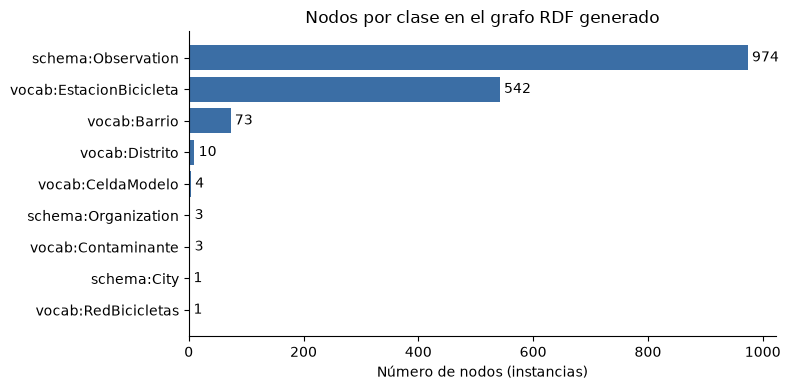

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
orden = tabla.sort_values('Nodos')
barras = ax.barh(orden['Clase'], orden['Nodos'], color='#3b6ea5')
ax.bar_label(barras, padding=3)
ax.set_xlabel('Número de nodos (instancias)')
ax.set_title('Nodos por clase en el grafo RDF generado')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Integración movilidad + calidad del aire

La prueba de que las fuentes quedaron **enlazadas**: partiendo de las estaciones (Fuente 1) se llega, a través
de la celda común, a las observaciones de NO₂ (Fuente 2). Consulta guardada en `sparql/03_estacion_aire.rq`.

In [23]:
consulta = DIR_E3 / 'sparql' / '03_estacion_aire.rq'
res = total.query(consulta.read_text(encoding='utf-8'))
pd.DataFrame([(r.celda.n3(total.namespace_manager), int(r.estaciones), float(r.no2_medio)) for r in res],
             columns=['Celda', 'Estaciones', 'NO2 medio (μg/m³)'])

,Celda,Estaciones,NO2 medio (μg/m³)
0,data:celda_41.35_2.25,6,17.57
1,data:celda_41.45_2.15,193,32.05
2,data:celda_41.35_2.15,301,27.68


Ahora cada celda tiene su propio valor medio de NO₂ (con los datos del Entregable 2 las dos celdas daban
el mismo valor, 27.68). La celda `celda_41.45_2.25` no aparece porque no tiene observaciones.

**Comprobación del enlace de las tres fuentes** (`sparql/05_enlace_fuentes.rq`): cuántas estaciones llegan a un
barrio, a una celda y a datos de aire.

In [24]:
def consultar(nombre):
    res = (total + vocab).query((DIR_E3 / 'sparql' / f'{nombre}.rq').read_text(encoding='utf-8'))
    return pd.DataFrame([[v.toPython() if v is not None else None for v in fila] for fila in res],
                        columns=[str(v) for v in res.vars])
consultar('05_enlace_fuentes')

,estaciones,estaciones_en_barrio,estaciones_en_celda,estaciones_con_datos_aire
0,542,542,542,500


**Tabla de evidencia** (`sparql/06_integracion_movilidad_aire.rq`): una fila por estación con su barrio, distrito,
bicicletas, anclajes y el aire de su celda a la hora H. Recorre las tres fuentes en una sola consulta; en GraphDB
su resultado se exporta a `E3_rdf/graphdb/integracion_movilidad_aire.csv`.

In [25]:
integracion = consultar('06_integracion_movilidad_aire')
print('Filas:', len(integracion), '| con datos de aire:', int(integracion.no2.notna().sum()))
integracion.head(8)

Filas: 542 | con datos de aire: 500


,estacion,barrio,distrito,bicicletas,anclajes,celda,no2,pm10,pm25
0,"AV. FRANCESC CAMBÓ, 10","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,7,17,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
1,"AV. MARQUÉS DE L'ARGENTERA, 15","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,9,17,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
2,"AV. MARQUÉS DE L'ARGENTERA, 3","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,4,12,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
3,"AV. MARQUÉS DE L'ARGENTERA,13","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,9,17,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
4,"C/ COMERÇ, 36","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,6,10,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
5,"C/ GOMBAU, 24","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,6,14,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
6,"C/ MÉNDEZ NÚÑEZ, 16","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,10,11,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2
7,"C/ SANT PERE MÉS ALT, 4","Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,6,15,"Celda CAMS 41.35, 2.15",17.2,4.8,2.2


**Resumen por distrito** (`sparql/07_resumen_por_distrito.rq`): sube por la jerarquía Estación → Barrio → Distrito.

In [26]:
consultar('07_resumen_por_distrito')

,distrito,barrios_con_estaciones,estaciones,bicicletas_disponibles,no2_medio
0,Eixample,6,114,452,17.8
1,Sant Martí,10,93,1220,18.5
2,Ciutat Vella,4,62,328,17.2
3,Sants-Montjuïc,8,57,452,17.2
4,Sant Andreu,7,48,447,20.5
5,Horta-Guinardó,8,40,70,20.5
6,Sarrià-Sant Gervasi,5,39,20,18.4
7,Les Corts,3,37,74,17.2
8,Nou Barris,10,28,89,20.5
9,Gràcia,4,24,31,20.1


## 13. Almacenamiento en GraphDB

GraphDB 10.8.5 se ejecuta en Docker con `docker compose up -d` (archivo `docker-compose.yml` en la raíz: datos en un
volumen persistente y memoria ajustada para las consultas con `GROUP BY`).
El script `cargar_graphdb.py` usa la API REST de GraphDB para:
1. crear el repositorio `bcn-kg` (ruleset RDFS-Plus Optimized);
2. importar los cuatro archivos (vocabulario, Bicing, calidad del aire y barrios) en **un solo grafo** `graph/bcn-kg`,
   para que las tres fuentes queden conectadas;
3. ejecutar las consultas `sparql/01–07` (verificación e integración) y `sparql/pc01–pc15`, guardar sus resultados en
   `E3_rdf/graphdb/` y exportar la tabla de evidencia a CSV;
4. registrar todas las consultas como **consultas guardadas** del Workbench.

In [27]:
ver_codigo(cargar_graphdb.importar)

```python
def importar(base: str) -> None:
    """Sube los archivos Turtle (modelo + las tres fuentes) al mismo grafo."""
    contexto = urllib.parse.quote(f"<{GRAFO}>")
    for ruta in ARCHIVOS:
        peticion(f"{base}/repositories/{REPO}/statements?context={contexto}", "POST",
                 ruta.read_bytes(), {"Content-Type": "text/turtle"})
        print(f"Importado {ruta.relative_to(RAIZ)} -> <{GRAFO}>")
```

Resultados devueltos por **GraphDB** (sin inferencia), comparados con los calculados localmente con rdflib en la
sección 11: deben coincidir exactamente.

In [28]:
import json
dir_gdb = DIR_E3 / 'graphdb'
gdb = pd.DataFrame(json.loads((dir_gdb / '01_nodos_por_clase.json').read_text(encoding='utf-8')))
gdb['Clase'] = [total.namespace_manager.normalizeUri(rdflib.URIRef(c)) for c in gdb['clase']]
gdb['Nodos GraphDB'] = gdb['nodos'].astype(int)
comparacion = tabla.merge(gdb[['Clase', 'Nodos GraphDB']], on='Clase', how='outer')
comparacion['Coincide'] = comparacion['Nodos'] == comparacion['Nodos GraphDB']
total_gdb = json.loads((dir_gdb / '02_total_tripletas.json').read_text(encoding='utf-8'))[0]['tripletas']
print('Tripletas explícitas en GraphDB:', total_gdb, '(datos + vocab.ttl)')
comparacion

Tripletas explícitas en GraphDB: 13874 (datos + vocab.ttl)


,Clase,Nodos,Nodos GraphDB,Coincide
0,schema:City,1,1,True
1,schema:Observation,974,974,True
2,schema:Organization,3,3,True
3,vocab:Barrio,73,73,True
4,vocab:CeldaModelo,4,4,True
5,vocab:Contaminante,3,3,True
6,vocab:Distrito,10,10,True
7,vocab:EstacionBicicleta,542,542,True
8,vocab:RedBicicletas,1,1,True


Las capturas de GraphDB (grafos importados, totales por clase, jerarquía de clases y visual graph) están en
`E3_rdf/informe/capturas/` y se incluyen en el informe.

## 14. Preguntas de competencia (PC1–PC15)

Cada pregunta tiene su consulta en `sparql/pcNN.rq`. Se ejecutan sobre el grafo local y se compara el número de
filas con lo que devolvió GraphDB. Las integradas usan la hora CAMS más cercana a la captura de Bicing (H = 17:00 UTC).

In [29]:
filas = []
for ruta in sorted((DIR_E3 / 'sparql').glob('pc*.rq')):
    n_local = len(list((total + vocab).query(ruta.read_text(encoding='utf-8'))))
    n_gdb = len(json.loads((dir_gdb / f'{ruta.stem}.json').read_text(encoding='utf-8')))
    filas.append((ruta.stem.upper(), ruta.read_text(encoding='utf-8').splitlines()[0].split('· ', 1)[-1], n_local, n_gdb))
pcs = pd.DataFrame(filas, columns=['PC', 'Pregunta', 'Filas (rdflib)', 'Filas (GraphDB)'])
pcs['Coincide'] = pcs['Filas (rdflib)'] == pcs['Filas (GraphDB)']
pd.set_option('display.max_colwidth', 120)
pcs

,PC,Pregunta,Filas (rdflib),Filas (GraphDB),Coincide
0,PC01,¿Qué estaciones tienen más de 10 bicicletas disponibles en el corte de captura?,116,116,True
1,PC02,¿Qué estaciones están saturadas (0 anclajes libres) y no admiten devoluciones?,8,8,True
2,PC03,"¿Qué estaciones están a menos de 1 km de Plaza Cataluña (41.38654, 2.16943)?",50,50,True
3,PC04,¿Qué estaciones tienen bicicletas eléctricas disponibles?,296,296,True
4,PC05,¿Cuáles son las 10 estaciones con mayor capacidad observada (bicicletas + anclajes libres)?,10,10,True
5,PC06,¿Cuál es el NO2 de la celda CAMS que contiene Plaza Cataluña a la hora H?,1,1,True
6,PC07,¿En qué celdas la media diaria de PM10 superó el valor guía OMS (45 µg/m³ en 24 h)?,6,6,True
7,PC08,¿Qué celdas registran PM2.5 horario > 25 µg/m³? Se listan los máximos por celda y si superan.,3,3,True
8,PC09,¿Cuál fue el mínimo y máximo de NO2 en cada celda durante el periodo capturado?,3,3,True
9,PC10,"¿Cuál es la razón media PM2.5 / PM10 en cada celda? (> 0.6 sugiere combustión; < 0.4, polvo)",3,3,True


Ejemplo de pregunta integrada (PC11): estaciones con 5 o más bicicletas en celdas con NO₂ ≤ 25 µg/m³ a la hora H.

In [30]:
print((DIR_E3 / 'sparql' / 'pc11.rq').read_text(encoding='utf-8'))
res = (total + vocab).query((DIR_E3 / 'sparql' / 'pc11.rq').read_text(encoding='utf-8'))
pd.DataFrame([(str(r.nombre), int(r.bicicletas), str(r.celda), float(r.no2)) for r in res],
             columns=['Estación', 'Bicicletas', 'Celda', 'NO2 (µg/m³)']).head(10)

# PC11 · [Integrada] ¿Qué estaciones con 5 o más bicicletas están en celdas con NO2 <= 25 µg/m³ a la hora H?
# H = "2026-11-12T17:00:00+00:00"^^xsd:dateTime (hora más cercana a la captura de Bicing).
PREFIX schema: <https://schema.org/>
PREFIX sosa: <http://www.w3.org/ns/sosa/>
PREFIX vocab: <http://example.org/bcn-kg/vocab#>
PREFIX data: <http://example.org/bcn-kg/data/>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

SELECT ?estacion ?nombre ?bicicletas ?celda ?no2 WHERE {
  ?estado schema:observationAbout ?e ; vocab:bicicletasDisponibles ?bicicletas .
  FILTER(?bicicletas >= 5)
  ?e schema:name ?nombre ; schema:containedInPlace ?c .
  ?o schema:observationAbout ?c ; sosa:observedProperty data:contaminante_NO2 ;
     schema:observationDate "2026-11-12T17:00:00+00:00"^^xsd:dateTime ; schema:value ?no2 .
  FILTER(?no2 <= 25)
  BIND(STRAFTER(STR(?e), STR(data:)) AS ?estacion) BIND(STRAFTER(STR(?c), STR(data:)) AS ?celda)
} ORDER BY DESC(?bicicletas) ?nombre



,Estación,Bicicletas,Celda,NO2 (µg/m³)
0,"AV. LITORAL, 172",41,celda_41.35_2.25,14.3
1,"RAMBLA DE GUIPÚSCOA, 43/FLUVIA",37,celda_41.45_2.15,20.5
2,"LA RAMBLA, 1",29,celda_41.35_2.15,17.2
3,"PG. ZONA FRANCA, 182",28,celda_41.35_2.15,17.2
4,"C/ FELIPE II, 112",26,celda_41.45_2.15,20.5
5,"C/ FERRAN JUNOY, 10",26,celda_41.45_2.15,20.5
6,"C/ ROC BORONAT, 134",26,celda_41.45_2.15,20.5
7,PL. TERESA DE CLARAMUNT/C/ DELS FERROCARILS,25,celda_41.35_2.15,17.2
8,"RAMBLA DE L'ONZE DE SETEMBRE, 31",25,celda_41.45_2.15,20.5
9,"C/ JANE ADDAMS, 26/ CRTA. DEL PRAT",24,celda_41.35_2.15,17.2


## 15. Conclusiones

- Se generaron tres archivos RDF (uno por fuente) bajo una única URI base y se cargaron en un solo grafo:
  estación → barrio → distrito → Barcelona y estación → celda CAMS, todo con `schema:containedInPlace`.
- Lo dinámico (estados y mediciones de aire) es `schema:Observation`, como pidió la docente.
- Los datos se validan automáticamente contra el dominio y rango declarados en `vocab.ttl`: 0 errores.
- El preprocesamiento detectó y corrigió una fusión incorrecta de celdas CAMS del Entregable 2, recuperando
  2 series de contaminantes que se habían perdido.
- Las 15 preguntas de competencia se responden con SPARQL y GraphDB devuelve los mismos resultados.
- La prueba con 2 filas, la validación y los tests (`pytest E3_rdf/tests`) permiten regenerar los datos de forma
  reproducible con `python E3_rdf/scripts/generar_rdf.py`.